# Dar_027 — Mini-RF manual CPR environmental/terrain context

## Questions
- Do PDS3/PDS4 dimensions, binary size and angular geotransform agree?
- How are ISIS special pixels and ordinary negative CPR separated?
- Which existing regional centres have nonnegative CPR support?
- How do CPR distributions differ by region and parent-shadow context?
- Are within-region CPR/terrain/visibility relationships supported?
- Which angular-support, mosaic and geometry limitations remain?

In [2]:
from pathlib import Path
import sys, json
ROOT = next(p for p in (Path.cwd(), *Path.cwd().parents)
            if (p/'outline.md').is_file() and (p/'notebooks').is_dir())
sys.path[:0] = [str(ROOT / "darrel stuff/EDA/shared"), str(ROOT / "darrel stuff/EDA/Moon/Stage3_Requirements"), str(ROOT)]
DATA = ROOT/'darrel stuff/data'
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display
import rasterio
from rasterio.enums import Resampling
from environment_workflow import LocalRun as Run, latest_completed_run
from decision_eda import accepted_input
import manual_raster_eda as methods
REGION_LIMIT=None
MANUAL_INVENTORY=DATA/'manifests/eda_datasets/20261107T182412585915Z/inventory.json'
CONTEXT_RUN='20261106T134155791814Z_c6f9ab'

def savefig(run, fig, name):
    fig.savefig(run.path(name+'.png'),dpi=120,bbox_inches='tight')
    display(fig); plt.close(fig)

def finite_hist(ax, values, label):
    finite=np.asarray(values); finite=finite[np.isfinite(finite)]
    if len(finite):
        ax.hist(finite,bins=70)
    else:
        ax.text(.5,.5,'No supported values in this declared sample',ha='center',transform=ax.transAxes)
    ax.set(xlabel=label,ylabel='Declared sample count')

def context_input(run):
    folder=latest_completed_run(ROOT,'analysis/dar_012_joint_environment',CONTEXT_RUN)
    path=accepted_input(run,folder,'native_center_context.csv.gz')
    frame=pd.read_csv(path)
    if frame.duplicated(['region','clon','clat']).any():raise ValueError('Duplicate context centres')
    if REGION_LIMIT is not None:
        preferred='A3CLR22_3_Faustini_Rim_A'
        regions=[preferred]+[r for r in sorted(frame.region.unique()) if r!=preferred]
        frame=frame.loc[frame.region.isin(regions[:REGION_LIMIT])].copy()
    return frame

def save_context_results(run, frame):
    summary=methods.regional_summary(frame)
    unique,relationships,contrasts=methods.relationship_tables(frame)
    frame.to_csv(run.path('source_at_environment_centres.csv.gz'),index=False,compression='gzip')
    summary.to_csv(run.path('regional_source_support.csv'),index=False)
    unique.to_csv(run.path('distinct_source_pixel_context.csv.gz'),index=False,compression='gzip')
    relationships.to_csv(run.path('within_region_relationships.csv'),index=False)
    contrasts.to_csv(run.path('parent_shadow_context_distributions.csv'),index=False)
    frame.groupby(['region','pixel_status']).size().rename('centres').reset_index().to_csv(run.path('centre_pixel_status_counts.csv'),index=False)
    display(summary); display(relationships)
    fig,axes=plt.subplots(1,2,figsize=(13,4),layout='constrained')
    labels=[r.split('_',2)[-1].replace('_',' ') for r in summary.region]
    axes[0].barh(labels,summary.support_fraction_of_context_centres)
    axes[0].set(xlabel='Supported fraction of existing thermal/context centres',xlim=(0,1),title='Point support, not area/footprint certification')
    for region,part in unique.groupby('region'):
        axes[1].scatter(part.slope_deg,part.analysis_value,s=3,alpha=.25,label=region.split('_',2)[-1])
    axes[1].set(xlabel='Existing LOLA slope (degrees)',ylabel='Source value (declared cohort)',title='Native-source-pixel context; not causal')
    if len(unique):axes[1].legend(fontsize=6)
    savefig(run,fig,'regional_support_and_slope_context')
    fig,ax=plt.subplots(figsize=(9,4),layout='constrained')
    supported=relationships.loc[relationships.status.eq('descriptive')]
    if len(supported):
        for region,part in supported.groupby('region'):
            ax.scatter(part.predictor,part.spearman_rho,label=region.split('_',2)[-1],s=25)
        ax.legend(fontsize=6)
    else:ax.text(.5,.5,'No supported within-region comparisons',ha='center',transform=ax.transAxes)
    ax.axhline(0,color='grey',lw=.5);ax.set(ylabel='Descriptive Spearman rho',ylim=(-1.05,1.05))
    savefig(run,fig,'within_region_context_associations')
    return summary,relationships,contrasts

## Sources and interpretation
Original source bytes stay in `darrel stuff/data/`, with explicit manual-import inventory/receipts. Their SHA-256 values are local integrity baselines, **not publisher checksums**. The `.xml.txt` label is parsed in place, not renamed or substituted.

- [ShadowCam archive SIS](https://pds.shadowcam.im-ldi.com/document/archsis.pdf): calibrated map products and uncontrolled geometric limitations.
- [Mini-RF global mosaic user guide](https://pds-geosciences.wustl.edu/lro/lro-l-mrflro-5-global-mosaic-v1/lromrf_1001/document/userguide.txt): mixed viewing geometry, uncontrolled/unorthorectified products and strip-gradient caveats.
- [USGS ISIS float32 special-pixel definitions](https://isis.astrogeology.usgs.gov/7.2.0/Object/Developer/_special_pixel_8h_source.html): NULL, low/high instrument and representation saturation are not measurements.

Relationships are within-region descriptions at distinct source pixels (context predictors use medians when several existing centres address one source pixel). Parent shadow classes are retained only when all contributing centres agree; mixed/unknown assignments stay separate. Twenty pairs is a descriptive/numerical safeguard, not independent-trial evidence or an operational requirement. No missing value is filled with zero.


Accepted local analysis/dar_012_joint_environment run: 20261106T134155791814Z_c6f9ab


,region,context_centres,inside_source_grid,ordinary_pixels,negative_ordinary_pixels,analysis_centres,distinct_analysis_source_pixels,support_fraction_of_context_centres,count,minimum,q10,median,q90,maximum
0,A3CLR22_10_Leibnitz_Beta_Plateau,4422,4422,4422,0,4422,4422,1.000000,4422,0.055616,0.251790,0.475346,0.887274,7.750666
1,A3CLR22_11_Malapert_Massif,7569,7569,7569,1,7568,7568,0.999868,7568,0.006224,0.274516,0.541995,1.078519,7.468066
2,A3CLR22_12_deGerlache_Kocher_Massif,6972,6972,6972,6,6966,6966,0.999139,6966,0.012568,0.248166,0.495410,1.000318,11.782415
3,A3CLR22_2_Haworth,15500,15500,15500,20,15480,15480,0.998710,15480,0.008179,0.198088,0.386859,0.744759,13.728843
4,A3CLR22_3_Faustini_Rim_A,6972,6972,6972,8,6964,6964,0.998853,6964,0.002063,0.186871,0.444938,0.941350,5.932249
5,A3CLR22_4_deGerlache_Rim_2,6889,6889,6762,9,6753,6753,0.980258,6753,0.000707,0.200177,0.449912,0.923416,31.594141
6,A3CLR22_5_Connecting_Ridge_Extension,7056,7056,4085,16,4069,4069,0.576672,4069,0.008479,0.173741,0.403984,0.859916,4.593702


,region,predictor,distinct_source_pixels,status,spearman_rho
0,A3CLR22_10_Leibnitz_Beta_Plateau,solar_visibility,4422,descriptive,0.081253
1,A3CLR22_10_Leibnitz_Beta_Plateau,earth_visibility,4422,descriptive,0.123921
2,A3CLR22_10_Leibnitz_Beta_Plateau,sky_view_sr,4422,descriptive,0.078131
3,A3CLR22_10_Leibnitz_Beta_Plateau,elevation_m,4422,descriptive,0.166925
4,A3CLR22_10_Leibnitz_Beta_Plateau,slope_deg,4422,descriptive,-0.081972
5,A3CLR22_11_Malapert_Massif,solar_visibility,7568,descriptive,0.128226
6,A3CLR22_11_Malapert_Massif,earth_visibility,7568,descriptive,0.177107
7,A3CLR22_11_Malapert_Massif,sky_view_sr,7568,descriptive,-0.046865
8,A3CLR22_11_Malapert_Massif,elevation_m,7568,descriptive,-0.030624
9,A3CLR22_11_Malapert_Massif,slope_deg,7568,descriptive,0.094669


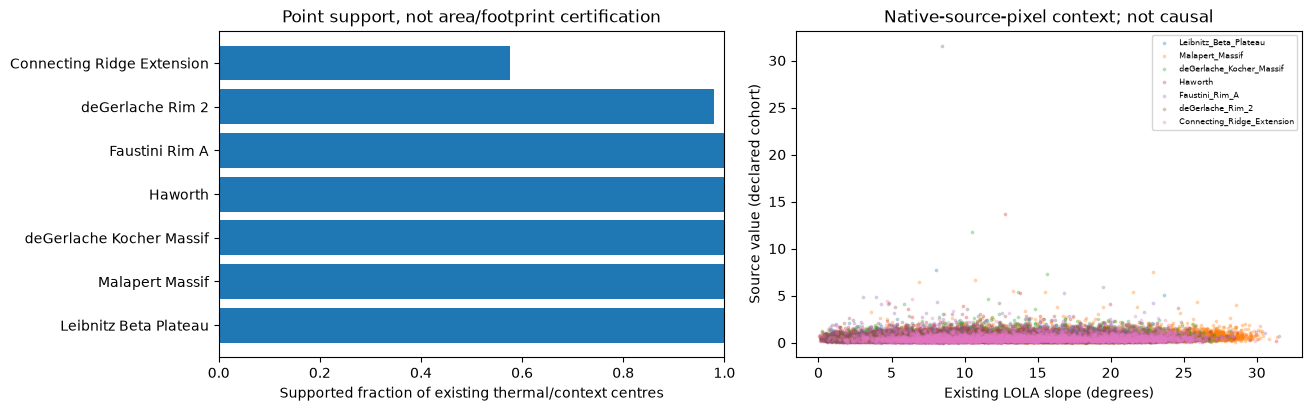

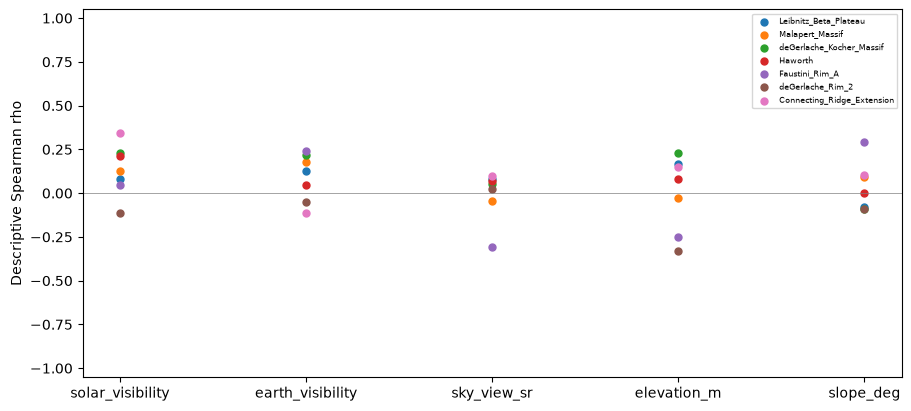

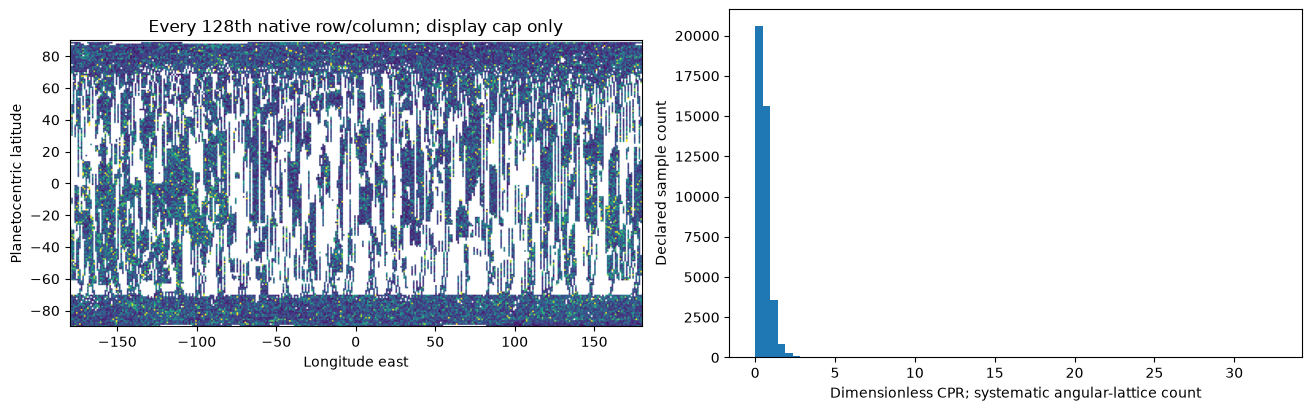

{'source_metadata': {'shape': [23040, 46080],
  'offset': 0,
  'ppd': 128.0,
  'radius_m': 1737400.0,
  'unit': 'dimensionless CPR',
  'map_pixel_scale_m': 236.90117518866998,
  'label_missing_constant': -1.7976931e+308,
  'label_missing_representable_float32': False,
  'special_pixel_policy': 'https://isis.astrogeology.usgs.gov/7.2.0/Object/Developer/_special_pixel_8h_source.html',
  'geometry_hold': 'Uncontrolled, unorthorectified multi-acquisition mosaic; viewing geometries are mixed'},
 'context_centres': 55380,
 'ordinary_signed_centres': 52282,
 'nonnegative_CPR_centres': 52222,
 'negative_ordinary_centres': 60,
 'regions_with_nonnegative_CPR_support': 7,
 'global_native_lattice_shape': [180, 360],
 'global_native_lattice_statuses': {'valid': 41195, 'isis_null': 23605},
 'global_ordinary_negative_samples': 46,
 'relationship_statuses': {'descriptive': 35},
 'holds': ['Label missing_constant cannot be represented in float32; exact documented ISIS special bits decoded explicitly',


Completed: C:\Darrel\Self-Projects\1 group proj\NASA-Space-Apps-Challenge-2026\darrel stuff\data\processed\analysis\dar_027_minirf_manual\20261109T151407642696Z_f5474c


In [3]:
with Run(ROOT,'analysis/dar_027_minirf_manual',{'dataset':'D30','product':'global_cpr_128ppd_simp_0c',
    'region_limit':REGION_LIMIT,'global_native_stride':128,'minimum_relationship_pairs':20,
    'analysis_cohort':'ordinary finite nonnegative CPR; signed ordinary diagnostics retained'},
    'Moon/Dar_027_minirf_cpr_environment.ipynb') as run:
    run.input(Path(methods.__file__))
    paths=methods.manual_selection(DATA,MANUAL_INVENTORY,'D30',run)
    meta=methods.radar_definition(paths['label'],paths['detached'],paths['image'])
    frame=context_input(run)
    values,rows,cols,inside=methods.sample_radar(paths['image'],meta,frame.clon.to_numpy(),frame.clat.to_numpy())
    paired=methods.attach_pixels(frame,values,rows,cols,inside,nonnegative=True)
    sample=methods.radar_preview(paths['image'],meta,stride=128)
    status=methods.classify_pixels(sample)
    records=[]
    for name,mask in [('ordinary_signed',status=='valid'),('ordinary_nonnegative',(status=='valid') & (sample>=0))]:
        records.append({'cohort':name,**methods.distribution(sample[mask])})
    pd.DataFrame(records).to_csv(run.path('global_native_lattice_distributions.csv'),index=False)
    pd.Series(status.ravel()).value_counts().rename_axis('pixel_status').rename('pixels').to_csv(run.path('global_native_lattice_status_counts.csv'))
    summary,relationships,contrasts=save_context_results(run,paired)
    ordinary=(status=='valid') & (sample>=0)
    preview=np.where(ordinary,sample,np.nan)
    fig,axes=plt.subplots(1,2,figsize=(13,4),layout='constrained')
    finite=preview[np.isfinite(preview)]
    if len(finite):
        axes[0].imshow(preview,extent=(-180,180,-90,90),cmap='viridis',vmin=0,vmax=np.quantile(finite,.99))
    else:axes[0].text(.5,.5,'No supported CPR values in systematic sample',ha='center')
    axes[0].set(title='Every 128th native row/column; display cap only',xlabel='Longitude east',ylabel='Planetocentric latitude')
    finite_hist(axes[1],sample[ordinary],'Dimensionless CPR; systematic angular-lattice count')
    savefig(run,fig,'minirf_native_lattice_preview')
    findings={'source_metadata':meta,'context_centres':len(paired),
        'ordinary_signed_centres':int(paired.ordinary_pixel.sum()),'nonnegative_CPR_centres':int(paired.nonnegative_screen.sum()),
        'negative_ordinary_centres':int((paired.ordinary_pixel & paired.raw_value.lt(0)).sum()),
        'regions_with_nonnegative_CPR_support':int(summary.analysis_centres.gt(0).sum()),
        'global_native_lattice_shape':list(sample.shape),'global_native_lattice_statuses':pd.Series(status.ravel()).value_counts().to_dict(),
        'global_ordinary_negative_samples':int(((status=='valid') & (sample<0)).sum()),
        'relationship_statuses':relationships.status.value_counts().to_dict(),
        'holds':['Label missing_constant cannot be represented in float32; exact documented ISIS special bits decoded explicitly',
                 'Nonnegative CPR is a declared physical/descriptive screen, not a source quality flag; ordinary negatives retained separately',
                 'Global angular lattice is not equal-area; nominal 236.9 m map scale is not an isotropic polar ground footprint',
                 'Uncontrolled, unorthorectified mosaic mixes acquisitions/viewing geometry and may contain strip gradients',
                 'CPR is a scattering ratio, not proof of ice, rock abundance, soil strength or an operational preference',
                 'No p-values, calibrated predictive model, hard thresholds or scoring weights inferred']}
    run.path('findings.json').write_text(json.dumps(findings,indent=2,default=str),encoding='utf-8')
    display(findings)
OUT=run.directory;print('Completed:',OUT)